In [5]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [15]:
df = pd.read_csv("SMSSpamCollection", sep='\t', header=None, names=['label', 'text'])

In [16]:
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

In [ ]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['text'])
X = X.toarray() 
y = df['label'].values

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
class MultinomialNaiveBayes:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.class_count = len(self.classes)
        self.feature_count = X.shape[1]

        # Initialize prior and likelihood
        self.class_priors = np.zeros(self.class_count)
        self.likelihoods = np.zeros((self.class_count, self.feature_count))

        # Laplace smoothing
        alpha = 1

        for c in self.classes:
            X_c = X[y == c]
            class_idx = int(c)
            self.class_priors[class_idx] = X_c.shape[0] / X.shape[0]
            # Sum word counts for each feature
            total_count = np.sum(X_c, axis=0)
            self.likelihoods[class_idx] = (total_count + alpha) / (np.sum(total_count) + alpha * self.feature_count)

    def predict(self, X):
        log_probs = []

        for x in X:
            class_log_prob = []
            for idx, c in enumerate(self.classes):
                log_prior = np.log(self.class_priors[idx])
                log_likelihood = np.sum(x * np.log(self.likelihoods[idx]))
                total_log_prob = log_prior + log_likelihood
                class_log_prob.append(total_log_prob)
            log_probs.append(np.argmax(class_log_prob))
        
        return np.array(log_probs)


In [12]:
model = MultinomialNaiveBayes()
model.fit(X_train, y_train)

In [13]:
y_pred = model.predict(X_test)

In [14]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

Accuracy: 0.9856502242152466
Classification Report:
               precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.94      0.95      0.95       149

    accuracy                           0.99      1115
   macro avg       0.97      0.97      0.97      1115
weighted avg       0.99      0.99      0.99      1115



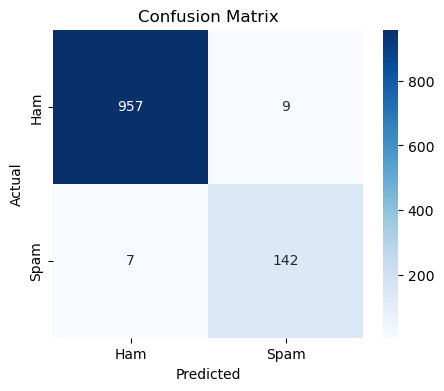

In [19]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [20]:
import pickle

with open('multinomial_naive_bayes_model.pkl', 'wb') as f:
    pickle.dump(model, f)

In [21]:
message = "Congratulations! You've won a free ticket. Call now to claim."

message_vec = vectorizer.transform([message]).toarray()

prediction = model.predict(message_vec)[0]

result = 'Spam' if prediction == 1 else 'Ham'
print(f"Message: {message}\nPrediction: {result}")

Message: Congratulations! You've won a free ticket. Call now to claim.
Prediction: Spam
